# Εργασία 2025-26

**Μάθημα: Αναγνώριση Προτύπων και Μηχανική Μάθηση**  
**Ονοματεπώνυμο: Δημόπουλος Μάριος-Γεώργιος, Παπαχριστοδούλου Γεωργία**  
**ΑΕΜ: 10930, 11177**


# Μέρος Δ: Data classification

In [ ]:
# Εισαγωγή όλων των απαραίτητων βιβλιοθηκών και εργαλείων που θα χρησιμοποιηθούν.
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import StackingClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier

# Θέτω global variable για το random state, για πιο εύκολη ρύθμιση του κώδικα.
RANDOM_STATE = 4

In [ ]:
# Φόρτωη του datasetTV.csv. Στη συνέχεια, γίνεται διαχωρισμός των χαρακτηριστικών (Χ) και της ετικέτας (y).
data = pd.read_csv('datasetTV.csv', header=None)

X = data.iloc[:, :-1]
y = data.iloc[:, -1]

# Διαχωρισμός του dataset σε training kai validation set, προκειμένου να γίνει το evalutaion των μοντέλων.
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

In [ ]:
# Έλεγχος της κατανομής των κλάσεων στο training set. Από το output είναι φανερό ότι οι κλάσεις είναι ισορροπημένες,
# οπότε δεν χρειάζεται να γίνουν επιπλέον ενέργειες για την αντιμετώπιση του imbalanced dataset (Oversampling, undersampling etc).
pd.Series(y_train).value_counts()

,count
224,
5,1338
1,1327
3,1315
2,1290
4,1287


In [ ]:
# Σε αυτό το cell, γίνεται έλεγχος για την ύπαρξη υψηλής συχέτισης μεταξύ των χαρακτηριστών.
# (Έχω θέσει threshold το 0.9). Επίσης, από το αποτέλεσμα είναι φανερό πως δεν υπάρχει υψηλή συσχέτιση μεταξύ των χαρακτηριστών.
print(X_train.shape)
print(X_val.shape)

corr = X_train.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr_features = [c for c in upper.columns if any(upper[c] > 0.9)]

X_train = X_train.drop(columns=high_corr_features)
X_val = X_val.drop(columns=high_corr_features)

print(X_train.shape)
print(X_val.shape)

(6557, 224)
(2186, 224)
(6557, 224)
(2186, 224)


In [ ]:
# Πρώτο μοντέλο: Logistic Regression
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(random_state=RANDOM_STATE))
])

lr_param_grid = {
    'lr__C': [0.01, 0.1, 1],
    'lr__solver': ['lbfgs'],    # best parameters: 'lr__C': 0.01, 'lr__max_iter': 1000, 'lr__solver': 'lbfgs'
    'lr__max_iter': [1000]
}

# Δεύτερο μοντέλο: Random Forest Classifier (Bagging)
rfc_pipeline = Pipeline([
    ("rfc", RandomForestClassifier(random_state=RANDOM_STATE))
])

rfc_param_grid = {
    'rfc__n_estimators': [200, 300],
    'rfc__max_depth': [None],
    'rfc__min_samples_leaf': [1, 2],      # best parameters: 'rfc__max_depth': None, 'rfc__max_features': 'sqrt', 'rfc__min_samples_leaf': 1, 'rfc__min_samples_split': 2, 'rfc__n_estimators': 200
    'rfc__max_features': ['sqrt']
}

# Τρίτο μοντέλο: Gradient Boosting Classifier (Boosting)
gbc_pipeline = Pipeline([
    ("gbc", GradientBoostingClassifier(random_state=RANDOM_STATE))
])

gbc_param_grid = {
    'gbc__n_estimators': [50, 100],
    'gbc__learning_rate': [0.05, 0.1],  # best parameters: 'gbc__learning_rate': 0.1, 'gbc__max_depth': 4, 'gbc__n_estimators': 50
    'gbc__max_depth': [3, 4]
}

# Τέταρτο μοντέλο: Support Vector Classifier
svc_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(probability=True, random_state=RANDOM_STATE))
])

svc_param_grid = {
    'svc__C': [5, 10],
    'svc__kernel': ['rbf'], # best parameters: 'svc__C': 5, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'
    'svc__gamma': ['scale']
}


In [ ]:
# Στο all_results αποθηκεύονται τα τελικά αποτελέσματα από την αξιολόγηση κάθε μοντέλου.
all_results = {}


# Ορίζω τις συναρτήσεις: evaluate_model (για αξιολόγηση του μοντέλου) και tune_model (για Hyperparameter tuning κάθε μοντέλου).
def evaluate_model(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    accuracy = round(accuracy_score(y_true, y_pred)*100,2)
    precision = round(precision_score(y_true, y_pred, average='weighted')*100,2)
    recall = round(recall_score(y_true, y_pred, average='weighted')*100,2)
    f1 = round(f1_score(y_true, y_pred, average='weighted')*100,2)

    results = {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
    }

    print("Evaluation Metrics:")
    for metric, value in results.items():
        print(f"{metric}: {value}%")

    print("\nMulticlass problem detected - showing confusion matrix...")
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(8, 6))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap="Blues", ax=ax, colorbar=False)
    plt.show()

    return results

def tune_model(model_name,pipeline, param_grid, X_train, y_train, X_val, y_val, return_model=False):
    grid_search = GridSearchCV(pipeline, param_grid, cv=3, scoring='f1_weighted', n_jobs=-1, verbose=3)

    grid_search.fit(X_train, y_train)

    print(f"Best Hypermarameters for {model_name}: {grid_search.best_params_}")

    best_model = grid_search.best_estimator_

    y_val_pred = best_model.predict(X_val)

    result = evaluate_model(y_val, y_val_pred)

    all_results[model_name] = result

    if return_model:
        return grid_search.best_estimator_



Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best Hypermarameters for Logistic Regression: {'lr__C': 0.01, 'lr__max_iter': 1000, 'lr__solver': 'lbfgs'}
Evaluation Metrics:
accuracy: 79.28%
precision: 79.17%
recall: 79.28%
f1: 79.18%

Multiclass problem detected - showing confusion matrix...


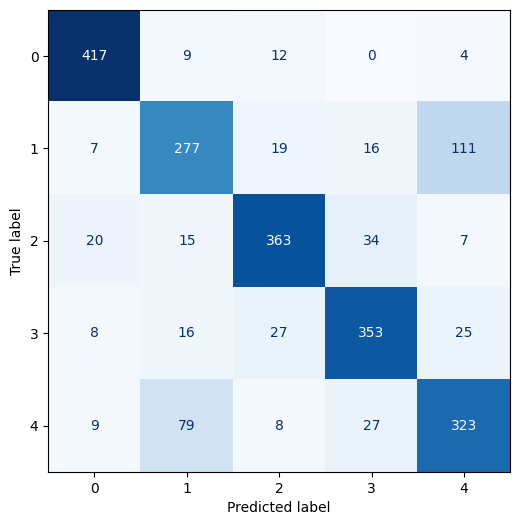

In [ ]:
# Κάνω tune το πρώτο μοντέλο: Logistic Regression. Η συνάρτηση tune_model επιστρέφει το καλύτερο μοντέλο με τα βέλτιστα hyperparameters,
# και αποθηκεύεται στη μεταβλητή best_lr (χρησιμοποιείται αργότερα στο stacking).
best_lr = tune_model("Logistic Regression", lr_pipeline, lr_param_grid, X_train, y_train, X_val, y_val, return_model=True)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best Hypermarameters for RandomForestClassifier: {'rfc__max_depth': None, 'rfc__max_features': 'sqrt', 'rfc__min_samples_leaf': 1, 'rfc__n_estimators': 300}
Evaluation Metrics:
accuracy: 82.66%
precision: 82.52%
recall: 82.66%
f1: 82.57%

Multiclass problem detected - showing confusion matrix...


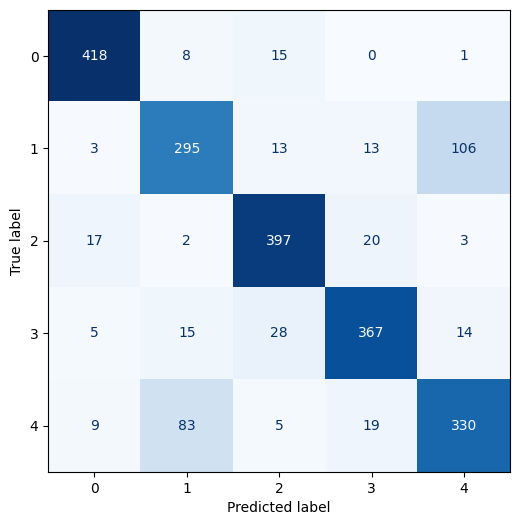

In [ ]:
# Κάνω tune το δεύτερο μοντέλο: Random Forest Classifier. Η συνάρτηση tune_model επιστρέφει το καλύτερο μοντέλο με τα βέλτιστα hyperparameters,
# και αποθηκεύεται στη μεταβλητή best_rfc (χρησιμοποιείται αργότερα στο stacking).
best_rfc = tune_model("RandomForestClassifier", rfc_pipeline, rfc_param_grid, X_train, y_train, X_val, y_val, return_model=True)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Hypermarameters for GradientBoostingClassifier: {'gbc__learning_rate': 0.1, 'gbc__max_depth': 4, 'gbc__n_estimators': 100}
Evaluation Metrics:
accuracy: 82.02%
precision: 82.11%
recall: 82.02%
f1: 82.02%

Multiclass problem detected - showing confusion matrix...


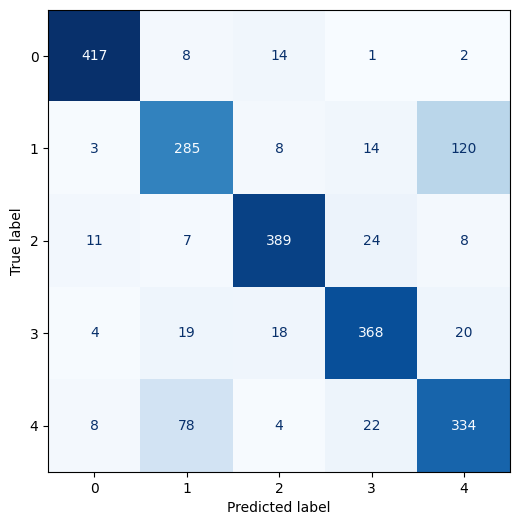

In [ ]:
# Κάνω tune το τρίτο μοντέλο: Gradient Boosting Classifier. Η συνάρτηση tune_model επιστρέφει το καλύτερο μοντέλο με τα βέλτιστα hyperparameters,
# και αποθηκεύεται στη μεταβλητή best_gbc (χρησιμοποιείται αργότερα στο stacking).
best_gbc = tune_model("GradientBoostingClassifier", gbc_pipeline, gbc_param_grid, X_train, y_train, X_val, y_val, return_model=True)

Fitting 3 folds for each of 2 candidates, totalling 6 fits
Best Hypermarameters for SVC: {'svc__C': 5, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}
Evaluation Metrics:
accuracy: 86.23%
precision: 86.33%
recall: 86.23%
f1: 86.21%

Multiclass problem detected - showing confusion matrix...


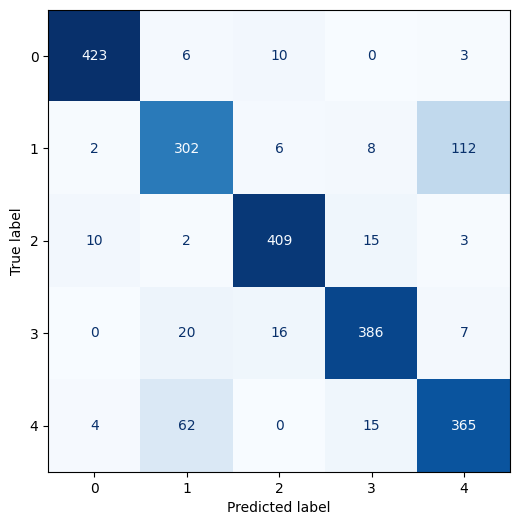

In [ ]:
# Κάνω tune το τέταρτο μοντέλο: Support Vector Classifier. Η συνάρτηση tune_model επιστρέφει το καλύτερο μοντέλο με τα βέλτιστα hyperparameters,
# και αποθηκεύεται στη μεταβλητή best_svc (χρησιμοποιείται αργότερα στο stacking).
best_svc =tune_model("SVC", svc_pipeline, svc_param_grid, X_train, y_train, X_val, y_val, return_model=True)

Evaluation Metrics:
accuracy: 87.1%
precision: 87.28%
recall: 87.1%
f1: 87.13%

Multiclass problem detected - showing confusion matrix...


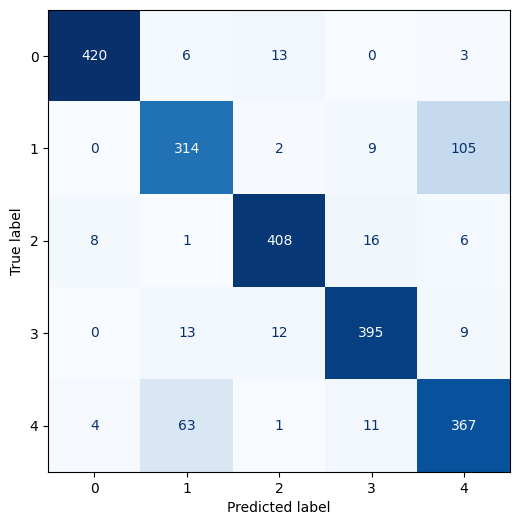

In [ ]:
# θέτω τα estimators με τα base-models και το meta-model, για το Stacking Classifier.
estimators = [
    ('lr', best_lr),
    ('rfc', best_rfc),
    ('gbc', best_gbc),
    ('svc', best_svc)
]

meta_model = LogisticRegression(C=1.0, max_iter=2000, random_state=RANDOM_STATE)

stacking_clf = StackingClassifier(
    estimators=estimators,
    final_estimator=meta_model,
    cv=3,
    stack_method='predict_proba',
    n_jobs=-1
)

stacking_clf.fit(X_train, y_train)
y_val_pred_stack = stacking_clf.predict(X_val)

all_results["Stacking Classfier"] = evaluate_model(y_val, y_val_pred_stack)

In [ ]:
# Εμφάνιση των τελικών αποτελεσμάτων από την αξιολόγηση κάθε μοντέλου.
display(pd.DataFrame(all_results).T)

,accuracy,precision,recall,f1
Logistic Regression,79.28,79.17,79.28,79.18
RandomForestClassifier,82.66,82.52,82.66,82.57
GradientBoostingClassifier,82.02,82.11,82.02,82.02
SVC,86.23,86.33,86.23,86.21
Stacking Classfier,87.10,87.28,87.10,87.13


In [ ]:
# Από τον παραπάνω πίνακα, είναι φανερό ότι το Stacking Classifier ξεπερνά σε απόδοση όλα τα υπόλοιπα μοντέλα.
# Οπότε το τελικό prediction στο testset θα γίνει με αυτό το μοντέλο.
X_test = np.loadtxt('datasetTest.csv', delimiter=',')

X_test = pd.DataFrame(X_test, columns=X_train.columns)  # Επιβάλλω στα X_test και X, να έχουν τα ίδια features με X_train. Αυτό γιατί σε παραπάνω cell έχω υπολογίσει τα
X = pd.DataFrame(X, columns=X_train.columns)            # features που είναι highly correlated και τα κάνω drop από το X_train. Έτσι το X, X_train, και X_test αναφέρονται όλα
                                                        # ίδιο dimension. (Βέβαια στην συγκεκριμένη περίπτωση δεν υπήρχαν highly correlated features, οπότε δεν αλλάζει το feature dimension).
stacking_clf.fit(X, y)

labelsX = stacking_clf.predict(X_test)

In [ ]:
labelsX = np.asarray(labelsX).reshape(-1)

assert labelsX.ndim == 1
assert labelsX.shape[0] == X_test.shape[0]

np.save("labelsX.npy", labelsX)

In [ ]:
from google.colab import files
files.download("labelsX.npy")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>